# Clasificación de 3 escenas con DenseNet121

DenseNet121 es una red no secuencial: dentro de cada bloque denso, cada capa
recibe concatenadas las salidas de todas las capas anteriores. Así reutiliza
características y el gradiente llega mejor a las primeras capas.

Partimos de DenseNet121 preentrenada en ImageNet y la ajustamos en dos fases:

1. **Base congelada**: solo se entrena la cabeza nueva, con `Adam(1e-3)`.
2. **Fine-tuning**: descongelamos las últimas 40 capas, salvo las
   `BatchNormalization`, y seguimos con `Adam(1e-5)`. Las `BatchNormalization`
   se quedan congeladas para no recalcular sus estadísticas con solo 610
   imágenes.

El modelo se carga desde `resultados/densenet/`; con `FORCE_RETRAIN = True` se
reentrena.

## Configuración

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from keras import layers
from keras.applications import DenseNet121
from keras.applications.densenet import preprocess_input
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam

import common_3scenes as cs

FORCE_RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(cs.SEED)
np.random.seed(cs.SEED)

I0000 00:00:1794894370.369689  215841 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794894371.391032  215841 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Carga del dataset y split común

In [2]:
data = cs.load_split_data()
X_train = data["X_train"].astype("float32")
X_val = data["X_val"].astype("float32")
X_test = data["X_test"].astype("float32")
y_train_labels = data["y_train"]
y_val_labels = data["y_val"]
y_test_labels = data["y_test"]
test_paths = data["test_paths"]

y_train = cs.one_hot(y_train_labels)
y_val = cs.one_hot(y_val_labels)

print("Train:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Distribución de test:", {name: int(np.sum(y_test_labels == name)) for name in cs.CLASSES})

Train: (610, 128, 128, 3) | Validación: (108, 128, 128, 3) | Test: (240, 128, 128, 3)
Distribución de test: {'coast': 90, 'forest': 82, 'highway': 68}


## Modelo, entrenamiento y evaluación

`Input(128, 128, 3)` → augmentación (flip horizontal, rotación 0.08, zoom 0.10
y traslación 0.08) → `preprocess_input` de DenseNet → `DenseNet121` sin su
cabeza de ImageNet → `GlobalAveragePooling2D` → `Dropout(0.35)` →
`Dense(3, softmax)`. Cada fase dura como máximo 12 épocas con batch de 32,
`EarlyStopping` sobre `val_accuracy` y `ReduceLROnPlateau` sobre `val_loss`.

In [3]:
def build_densenet():
    inputs = layers.Input(shape=(128, 128, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = layers.Lambda(preprocess_input, name="densenet_preprocessing")(x)

    base = DenseNet121(include_top=False, weights="imagenet", input_shape=(128, 128, 3))
    base.trainable = False

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(len(cs.CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="densenet121_3scenes")
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model


def fit_densenet(model):
    base = model.get_layer("densenet121")
    phase1_callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
    history_phase1, seconds_phase1 = cs.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=12,
        batch_size=32,
        callbacks=phase1_callbacks,
    )

    for layer in base.layers[-40:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-5),
        metrics=["accuracy"],
    )

    phase2_callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ]
    history_phase2, seconds_phase2 = cs.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=12,
        batch_size=32,
        callbacks=phase2_callbacks,
    )

    history = pd.concat(
        [pd.DataFrame(history_phase1.history), pd.DataFrame(history_phase2.history)],
        ignore_index=True,
    )
    history.index = np.arange(1, len(history) + 1)
    return model, history, seconds_phase1 + seconds_phase2


def evaluate_densenet(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cs.predict_keras(model, X_test)
    predicted = np.array(cs.CLASSES)[predicted_idx]
    metrics = cs.compute_metrics(
        name="DenseNet121",
        family="DL (non-sequential)",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history),
        hyperparameters={
            "base": "DenseNet121 ImageNet",
            "input": 128,
            "phase1_lr": 1e-3,
            "phase2_lr": 1e-5,
            "batch_size": 32,
            "epochs_phase1": 12,
            "epochs_phase2": 12,
            "dropout": 0.35,
            "fine_tuning_layers": 40,
        },
        notes="DenseNet121 pretrained on ImageNet with two-phase fine-tuning (BatchNorm layers stay frozen).",
    )
    cs.save_results(
        "densenet",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics

In [4]:
model, history, metrics, retrained = cs.load_or_train(
    "densenet",
    build_model=build_densenet,
    fit_model=fit_densenet,
    evaluate_model=evaluate_densenet,
    force=FORCE_RETRAIN,
)
print("Accuracy en test:", round(metrics["accuracy"], 4))

[train] Training model in /home/chewi/Documentos/uni/vision-por-computador/guia-4/reto-1/resultados/densenet


E0000 00:00:1794894372.956787  215841 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



       0/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   32768/29084464 ━━━━━━━━━━━━━━━━━━━━ 47s 2us/step

   81920/29084464 ━━━━━━━━━━━━━━━━━━━━ 46s 2us/step

  147456/29084464 ━━━━━━━━━━━━━━━━━━━━ 35s 1us/step

... (71 outputs left out)

Epoch 12/12


20/20 - 5s - 232ms/step - accuracy: 0.9885 - loss: 0.0586 - val_accuracy: 0.9907 - val_loss: 0.0503 - learning_rate: 1.0000e-05


Restoring model weights from the end of the best epoch: 9.


Results saved to: /home/chewi/Documentos/uni/vision-por-computador/guia-4/reto-1/resultados/densenet
Accuracy en test: 0.9833


## Grad-CAM

Grad-CAM usa los gradientes de cada clase respecto a la última capa
convolucional (`conv5_block16_concat`) para marcar las zonas de la imagen que
más pesan en la decisión. Lo calculamos para una imagen de test y las tres
clases.

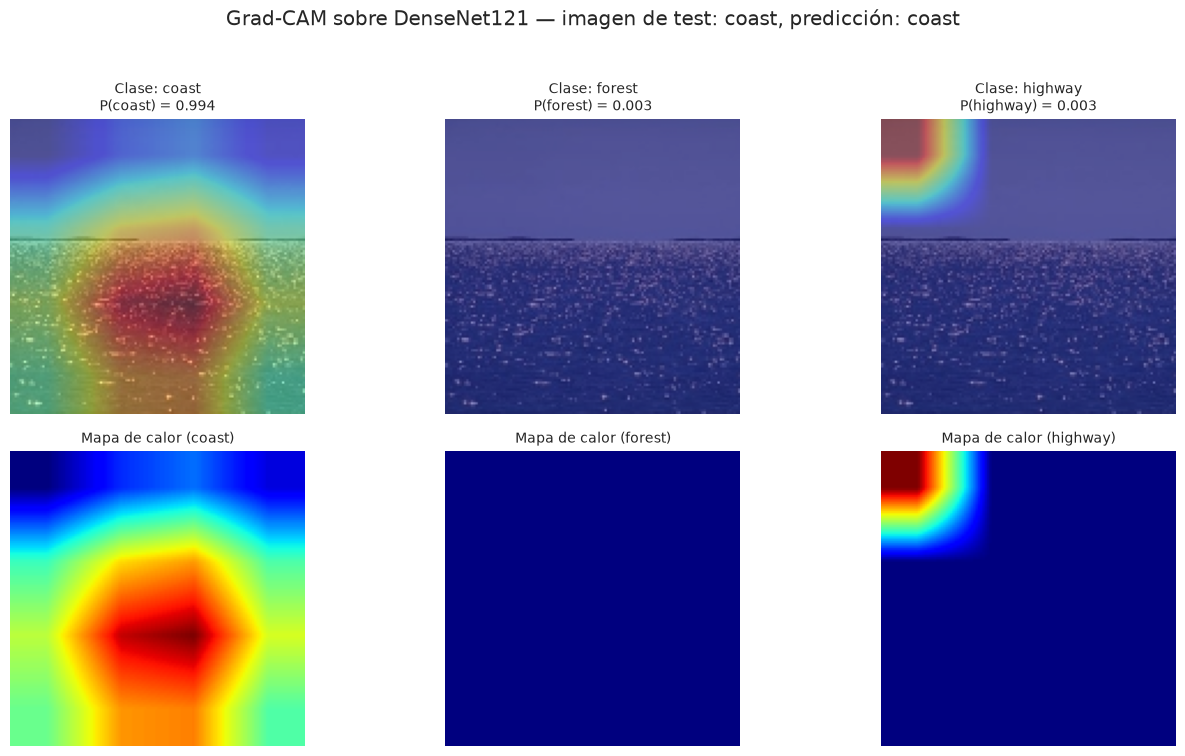

In [5]:
try:
    base = model.get_layer("densenet121")
    conv_layer = base.get_layer("conv5_block16_concat")
    grad_model = keras.Model(base.input, [conv_layer.output, base.output])

    gap = next(layer for layer in model.layers if isinstance(layer, layers.GlobalAveragePooling2D))
    dropout = next(layer for layer in model.layers if isinstance(layer, layers.Dropout))
    classifier = next(layer for layer in model.layers if isinstance(layer, layers.Dense))

    def grad_cam(image, class_index):
        with tf.GradientTape() as tape:
            conv_output, features = grad_model(
                preprocess_input(image[None].astype("float32")), training=False
            )
            predictions = classifier(dropout(gap(features), training=False))
            loss = predictions[:, class_index]
        gradients = tape.gradient(loss, conv_output)
        weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
        heatmap = tf.reduce_mean(conv_output[0] * weights, axis=-1)
        heatmap = tf.maximum(heatmap, 0)
        heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
        return heatmap.numpy()

    rng = np.random.default_rng(cs.SEED)
    index = int(rng.integers(len(X_test)))
    image = X_test[index]
    probabilities = model.predict(image[None], verbose=0)[0]

    fig, axes = plt.subplots(2, len(cs.CLASSES), figsize=(4.6 * len(cs.CLASSES), 7.4))
    for class_index, class_name in enumerate(cs.CLASSES):
        heatmap = grad_cam(image, class_index)
        heatmap = tf.image.resize(heatmap[..., None], (128, 128)).numpy()[..., 0]

        axes[0, class_index].imshow(image.astype("uint8"))
        axes[0, class_index].imshow(heatmap, cmap="jet", alpha=0.45)
        axes[0, class_index].set_title(
            f"Clase: {class_name}\nP({class_name}) = {probabilities[class_index]:.3f}",
            fontsize=10,
        )
        axes[0, class_index].axis("off")

        axes[1, class_index].imshow(heatmap, cmap="jet")
        axes[1, class_index].set_title(f"Mapa de calor ({class_name})", fontsize=10)
        axes[1, class_index].axis("off")

    predicted_index = int(np.argmax(probabilities))
    fig.suptitle(
        f"Grad-CAM sobre DenseNet121 — imagen de test: {y_test_labels[index]}, "
        f"predicción: {cs.CLASSES[predicted_index]}",
        y=1.02,
    )
    fig.tight_layout()
    cs.result_dir("densenet").mkdir(parents=True, exist_ok=True)
    fig.savefig(cs.result_dir("densenet") / "gradcam.png", dpi=150, bbox_inches="tight")
    plt.show()
except Exception as exc:
    print(f"[aviso] No se pudo generar el Grad-CAM: {exc}")

## Observaciones

* 98.33 % de accuracy en test, el mejor resultado del reto, con 23 épocas y
  unos 2 minutos de entrenamiento en CPU.
* En la imagen de costa, el Grad-CAM se concentra en la superficie del mar.
  Para bosque y autopista el mapa casi no se activa, lo que coincide con
  P(coast) = 0.994.